# 05 · Importancia de variables

Qué características del tuit usa el modelo de 24 variables para clasificar el sentimiento, y cuáles pesan de verdad. Este cuaderno **recalcula todo aquí**, con CPU, a partir de los datos del repositorio (no lee resultados guardados), y al final compara con las tablas que ya estaban en `docs/features/tablas/`.

Se mide de dos maneras, las dos sobre el conjunto de desarrollo (2.465 tuits) con el modelo entrenado solo con train:

1. **Importancia por permutación:** se desordena una columna de dev a la vez y se mide cuánto cae el Macro-F1.
2. **Ablación por grupo:** se reentrena el modelo sin un grupo de variables, y también solo con un grupo.

El modelo es una regresión logística balanceada sobre las 24 variables estandarizadas. No es el LLM: sirve para decidir qué pistas vale la pena ofrecer al agente de Percepción.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
for sub in ("features", "eda"):
    sys.path.insert(0, str(RAIZ / "scripts" / sub))
import feature_utils as F
import eda_utils as E

pd.set_option("display.width", 180, "display.max_colwidth", 80)
AZUL, GRIS = "#2a78d6", "#b8b7b0"
TABLAS = RAIZ / "docs" / "features" / "tablas"

corpus = E.cargar_corpus(RAIZ / "data")
print(corpus.split.value_counts().to_dict(), "| dev por variedad:", corpus[corpus.split == "dev"].variedad.value_counts().to_dict())

{'train': 4802, 'dev': 2465} | dev por variedad: {'ES': 581, 'MX': 510, 'PE': 498, 'UY': 486, 'CR': 390}


## 1 · Las 24 variables

Cinco grupos: estructural (6), expresividad (7), conversacional (4), fenómeno (4) y léxico (3). Se calculan con reglas simples sobre el texto. El léxico es una lista propia de unas 30 palabras por lado, sin validar.

In [2]:
cat = F.catalogo_features()
print(cat.grupo.value_counts().to_dict())
cat[["feature", "grupo", "tipo", "definicion"]]

{'expresividad': 7, 'estructural': 6, 'conversacional': 4, 'fenomeno': 4, 'lexico': 3}


,feature,grupo,tipo,definicion
0,n_caracteres,estructural,conteo,Longitud del tuit en caracteres.
1,n_palabras,estructural,conteo,Número de palabras (secuencias de letras).
2,long_media_palabra,estructural,razón,Caracteres de letras por palabra.
3,n_oraciones,estructural,conteo,Segmentos terminados en . ! ? (mínimo 1).
4,ratio_mayusculas,estructural,razón,Fracción de letras en mayúscula.
5,n_digitos,estructural,conteo,Cantidad de dígitos.
6,n_exclamaciones,expresividad,conteo,Signos ! en el tuit.
7,n_interrogaciones,expresividad,conteo,Signos ? en el tuit.
8,n_puntos_suspensivos,expresividad,conteo,Secuencias de 3 o más puntos.
9,n_alargamientos,expresividad,conteo,Letras repetidas 3 o más veces (holaaa).


## 2 · Importancia por permutación

Para cada variable se desordenan sus valores en dev, 15 veces, y se registra la caída promedio del Macro-F1. Una caída grande significa que el modelo dependía de esa variable. Como las demás se mantienen, es más confiable que mirar cada variable sola.

In [3]:
imp = F.importancia_permutacion(corpus)
imp

,feature,caida_macro_f1,desv,grupo
0,n_lex_positivo,0.0800,0.0071,lexico
1,n_lex_negativo,0.0261,0.0034,lexico
2,n_negaciones,0.0128,0.0042,fenomeno
3,n_intensificadores,0.0092,0.0032,lexico
4,n_exclamaciones,0.0092,0.0033,expresividad
5,empieza_con_mencion,0.0072,0.0032,conversacional
6,n_palabras,0.0055,0.0037,estructural
7,n_interrogaciones,0.0023,0.0024,expresividad
8,n_emoticonos,0.0007,0.0002,expresividad
9,tiene_url,0.0002,0.0004,conversacional


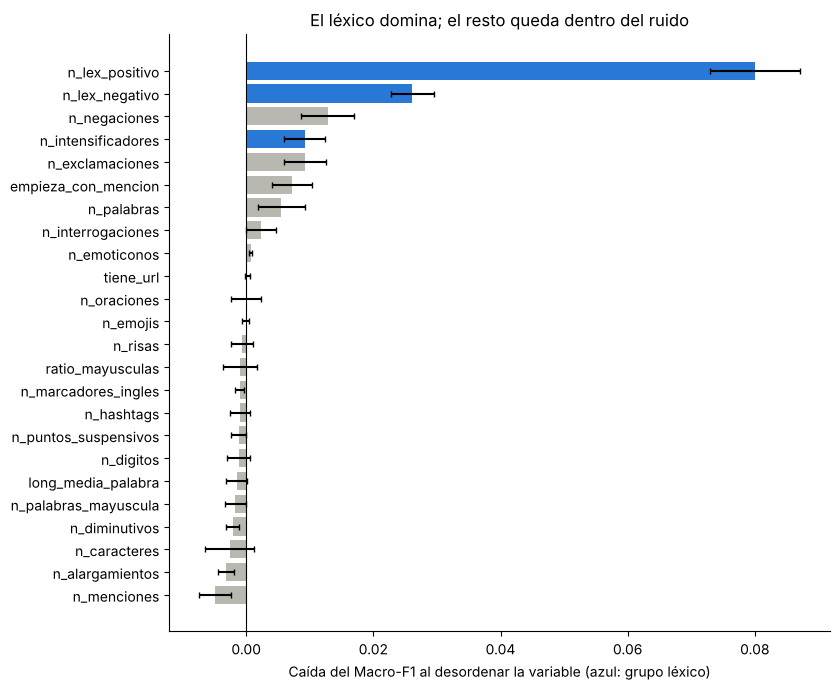

In [4]:
d = imp.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.5, 7))
ax.barh(d.feature, d.caida_macro_f1, xerr=d.desv, color=[AZUL if g == "lexico" else GRIS for g in d.grupo], ecolor="k", capsize=2)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Caída del Macro-F1 al desordenar la variable (azul: grupo léxico)")
ax.set_title("El léxico domina; el resto queda dentro del ruido")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

Las dos listas de valoración (`n_lex_positivo` y `n_lex_negativo`) son las que más pesan. Después vienen la negación, los intensificadores (que también son del grupo léxico) y las exclamaciones. Casi todas las demás caen entre −0,005 y +0,001, es decir, desordenarlas no cambia nada medible. Las caídas negativas son ruido.

## 3 · Ablación por grupo

Se reentrena el modelo quitando un grupo (queda con las variables restantes) y usando un solo grupo. El cambio de Macro-F1 contra el modelo completo lleva un intervalo del 95% por bootstrap pareado, porque todas las versiones se miden sobre los mismos tuits.

In [5]:
abl = F.ablacion_por_grupo(corpus)
abl

,configuracion,n_features,macro_f1_dev,cambio_vs_completo,ic_inf,ic_sup
0,Completo (5 grupos),24,0.5085,0.0000,0.0000,0.0000
1,Sin estructural,18,0.5067,-0.0017,-0.0099,0.0068
2,Sin expresividad,17,0.5174,0.0089,-0.0019,0.0201
3,Sin conversacional,20,0.5168,0.0083,-0.0054,0.0232
4,Sin fenomeno,20,0.5113,0.0028,-0.0080,0.0136
5,Sin lexico,21,0.4331,-0.0754,-0.0962,-0.0537
6,Solo estructural,6,0.3927,-0.1158,-0.1398,-0.0912
7,Solo expresividad,7,0.3542,-0.1543,-0.1783,-0.1285
8,Solo conversacional,4,0.3720,-0.1365,-0.1591,-0.1133
9,Solo fenomeno,4,0.3318,-0.1767,-0.2005,-0.1543


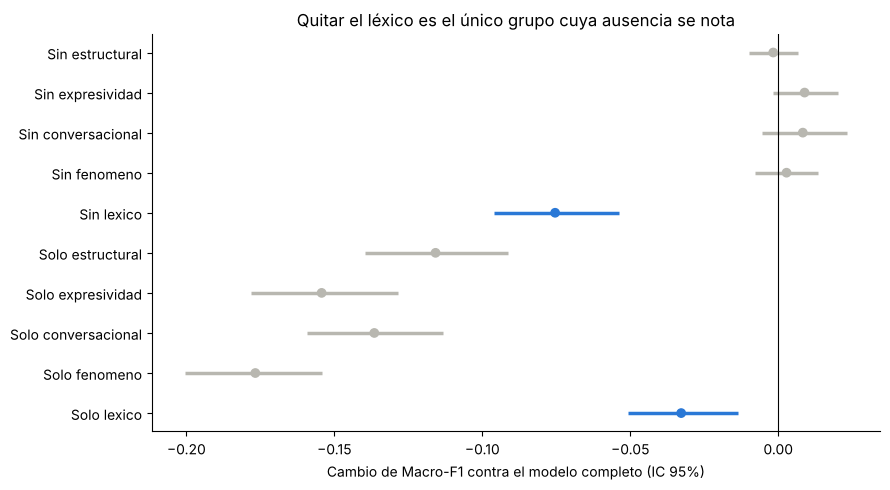

In [6]:
a = abl.iloc[1:].iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 5)); y = np.arange(len(a))
col = [AZUL if "lexico" in c.lower() or "léxico" in c.lower() else GRIS for c in a.configuracion]
ax.hlines(y, a.ic_inf, a.ic_sup, color=col, lw=2.5); ax.scatter(a.cambio_vs_completo, y, color=col, zorder=3)
ax.axvline(0, color="k", lw=0.8); ax.set_yticks(y, a.configuracion)
ax.set_xlabel("Cambio de Macro-F1 contra el modelo completo (IC 95%)")
ax.set_title("Quitar el léxico es el único grupo cuya ausencia se nota")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

- **Sin léxico** baja el Macro-F1 en 0,075. Es el único grupo cuyo intervalo no incluye el cero.
- **Sin ningún otro grupo** no cambia nada distinguible. Que el Macro-F1 suba un poco al quitar expresividad o conversacional no es una mejora: los intervalos incluyen el cero.
- **Solo léxico** (3 variables) llega a 0,48, contra 0,51 con las 24. Los demás grupos, cada uno solo, quedan entre 0,33 y 0,39.

## 4 · Comprobación contra las tablas del repositorio

Lo recalculado aquí debe coincidir con `docs/features/tablas/importancia_permutacion.csv` y `ablacion_por_grupo.csv`.

In [7]:
imp0 = pd.read_csv(TABLAS / "importancia_permutacion.csv")
abl0 = pd.read_csv(TABLAS / "ablacion_por_grupo.csv")
ok_imp = np.allclose(imp.set_index("feature").loc[imp0.feature, "caida_macro_f1"], imp0.caida_macro_f1, atol=1e-4)
ok_abl = np.allclose(abl.macro_f1_dev, abl0.macro_f1_dev, atol=1e-4)
print("importancia por permutación coincide:", ok_imp)
print("ablación por grupo coincide:", ok_abl)

importancia por permutación coincide: True
ablación por grupo coincide: True


## 5 · Por qué una caída pequeña no prueba que la variable no sirva

Cuando dos variables dicen casi lo mismo, el modelo puede apoyarse en cualquiera, y desordenar una sola casi no se nota. Estas son las parejas más correlacionadas.

In [8]:
pd.read_csv(TABLAS / "correlaciones_altas.csv")

,feature_a,feature_b,spearman_abs
0,n_caracteres,n_palabras,0.937
1,n_menciones,empieza_con_mencion,0.878


## Conclusiones

- **El léxico de valoración es lo único indispensable.** Quitarlo baja 0,075 de Macro-F1, y con solo sus 3 variables se llega a 0,48.
- **Pistas para el agente de Percepción:** además de las listas de valoración, tienen sentido la negación, los intensificadores y las exclamaciones. Emojis, emoticonos, enlaces, número de oraciones, risas y diminutivos no aportan en este modelo.
- **`empieza_con_mencion` pesa, pero con cuidado.** Las variables conversacionales se relacionan más con el país que con el sentimiento (ver `docs/features/RESUMEN_FEATURES.md`), así que puede ser un atajo.

## Límites

- La importancia es del modelo de 24 variables, no del LLM.
- Las variables correlacionadas se reparten la importancia.
- El léxico es una lista propia sin validar: su importancia mide esa lista, no el léxico de valoración en general.
- Todo se mide en dev, porque no existe partición de prueba. No se ajustó ningún hiperparámetro con esos datos.